> **Reference copy with outputs.** This notebook was run on Wolverine Glacier on 2026-10-22 (OGGM 1.6.3, preprocessed level 4, W5E5). It shows what the notebook should produce. To run it yourself, open [`notebooks/01_oggm_primer.ipynb`](../notebooks/01_oggm_primer.ipynb), not this copy.

# 01 · OGGM primer: what the model computes

OGGM chains four pieces. This notebook takes them in order on Wolverine and shows where
precipitation phase enters, and where velocity comes from.

1. **Climate at the glacier**: monthly temperature and precipitation at every flowline height.
2. **Surface mass balance**: a monthly temperature-index model with a rain/snow split.
3. **Ice thickness**: inverted from the mass balance by mass conservation.
4. **Ice flow**: the shallow-ice approximation moves ice down the flowline and gives velocity.

Main references: Maussion et al. (2019, GMD) for OGGM, Schuster et al. (2023) for the 1.6 mass
balance and calibration, Zekollari et al. (2022) for the dynamical spinup.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))
import warnings

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from oggm import cfg, tasks
from oggm.core.massbalance import MonthlyTIModel, MultipleFlowlineMassBalance

from wolverine_oggm import config, dynamics, phase, plotting

warnings.filterwarnings("ignore", category=RuntimeWarning)
plotting.set_style("paper")
gdir = config.get_glacier_directory()
fl = gdir.read_pickle("model_flowlines")[-1]
zice = fl.surface_h[fl.thick > 0]          # glacier surface only (the flowline continues down-valley)

## 1. Climate at each height

From a reference height $z_{ref}$ with temperature $T_{ref}$ (monthly, from W5E5):

$$T(z) = T_{ref} + \beta + \gamma\,(z - z_{ref}), \qquad \gamma = -6.5\ \mathrm{K\,km^{-1}}$$

$$P(z) = f_P\, P_{ref}$$

where $\beta$ is the calibrated `temp_bias` and $f_P$ the calibrated `prcp_fac`. Precipitation
has no elevation gradient. The precipitation factor carries all orographic enhancement and
undercatch correction as one number. Notebook 05 checks how SCHNAPS's own precipitation
compares.

<oggm.MassBalanceModel>
  Class: MonthlyTIModel
  Attributes:
    - hemisphere: nh
    - climate_source: GSWP3_W5E5
    - melt_f: 5.95
    - prcp_fac: 1.01
    - temp_bias: -3.07
    - bias: 0.00
    - rho: 900.0
    - t_solid: 0.0
    - t_liq: 2.0
    - t_melt: -1.0
    - repeat: False
    - ref_hgt: 878.0
    - ys: 1901
    - ye: 2019



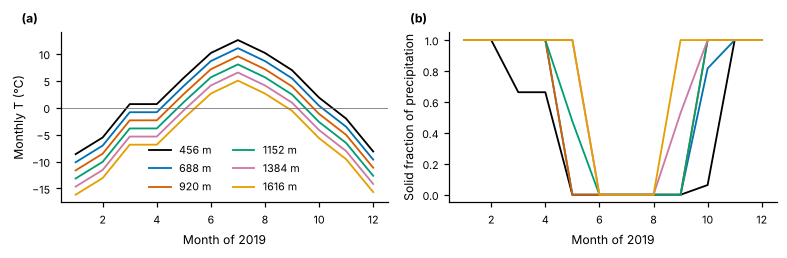

In [2]:
mb = MonthlyTIModel(gdir)
print(mb)
heights = np.linspace(zice.min(), zice.max(), 6).round()
y = config.calibration_years()[1]
temp, tmelt, prcp, prcpsol = mb._get_2d_annual_climate(heights, y)
fig, axes = plt.subplots(1, 2, figsize=(plotting.WIDTH_2COL, 2.4))
months = np.arange(1, 13)
for k, h in enumerate(heights):
    axes[0].plot(months, temp[k], label=f"{h:.0f} m")
    axes[1].plot(months, prcpsol[k] / prcp[k], label=f"{h:.0f} m")
axes[0].axhline(0, color=plotting.GREY, lw=0.5)
axes[0].set_ylabel("Monthly T (°C)")
axes[1].set_ylabel("Solid fraction of precipitation")
for ax in axes:
    ax.set_xlabel(f"Month of {y}")
axes[0].legend(frameon=False, ncol=2)
plotting.label_panels(axes)
fig.tight_layout()
plotting.test_mode_note(fig)

## 2. Mass balance and the rain/snow split

Each month, at each height:

$$\dot{m}(z) = P_{solid}(z) - \mu\, \max\big(T(z) - T_{melt},\, 0\big), \qquad T_{melt} = -1\,^{\circ}\mathrm{C}$$

with melt factor $\mu$ (`melt_f`). The solid precipitation comes from a **linear ramp on the
monthly mean temperature**:

$$P_{solid} = P \cdot \min\Big(1,\ \max\big(0,\ 1 - \tfrac{T - T_{solid}}{T_{liq} - T_{solid}}\big)\Big), \qquad T_{solid}=0\,^{\circ}\mathrm{C},\ T_{liq}=2\,^{\circ}\mathrm{C}$$

Rain does not add mass in this model (no refreezing). It runs off.

Two things matter for Wolverine.

* The ramp sees the **monthly mean**. A month averaging +1 °C at 1,000 m gets 50% snow
  whether it snowed in cold spells and rained in warm ones, or the other way round. Maritime
  storms often bring precipitation in the warmest part of a month.
* $T_{melt} = -1$ °C, below 0 °C, is how OGGM accounts for melt on days above freezing within
  months that average below it. Phase gets no such correction.

Notebook 03 replaces the ramp with other curves and accounts for the sub-monthly temperature
spread (`wolverine_oggm.massbalance.PhaseAwareTIModel`).

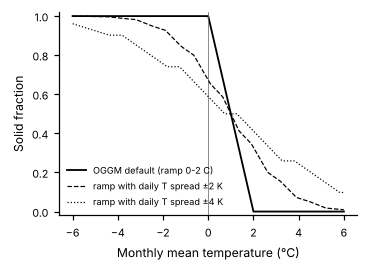

In [3]:
t = np.linspace(-6, 6, 241)
fig, ax = plt.subplots(figsize=(plotting.WIDTH_1COL, 2.4))
plotting.phase_curves(ax, [phase.STANDARD_CURVES["oggm"]], t)
for sd, ls in ((2.0, "--"), (4.0, ":")):
    ax.plot(t, phase.expected_solid_fraction(phase.STANDARD_CURVES["oggm"], t, sd), "k", ls=ls,
            lw=0.8, label=f"ramp with daily T spread ±{sd:.0f} K")
ax.set_xlabel("Monthly mean temperature (°C)")
ax.legend(frameon=False, fontsize=6)
plotting.test_mode_note(fig)

The mass-balance profile, averaged over the calibration period, with the contributions split
out:

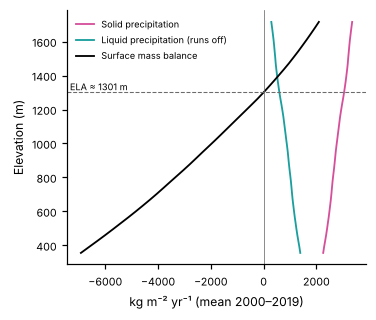

In [4]:
y0, y1 = config.calibration_years()
hh = np.linspace(zice.min() - 100, zice.max() + 100, 40)
acc = np.mean([mb.get_annual_climate(hh, yr)[3] for yr in range(y0, y1 + 1)], axis=0)
liq = np.mean([mb.get_annual_climate(hh, yr)[2] for yr in range(y0, y1 + 1)], axis=0) - acc
smb = np.mean([mb.get_annual_mb(hh, yr) for yr in range(y0, y1 + 1)], axis=0) * cfg.SEC_IN_YEAR * cfg.PARAMS["ice_density"]
fig, ax = plt.subplots(figsize=(plotting.WIDTH_1COL, 3))
ax.plot(acc, hh, color=plotting.SNOW, label="Solid precipitation")
ax.plot(liq, hh, color=plotting.RAIN, label="Liquid precipitation (runs off)")
ax.plot(smb, hh, color="k", label="Surface mass balance")
ax.axvline(0, color=plotting.GREY, lw=0.5)
ela = np.interp(0, smb, hh) if (smb.min() < 0 < smb.max()) else np.nan
ax.axhline(ela, color=plotting.GREY, ls="--", lw=0.7)
ax.text(ax.get_xlim()[0], ela, f" ELA ≈ {ela:.0f} m", va="bottom", fontsize=6)
ax.set_xlabel(f"kg m⁻² yr⁻¹ (mean {y0}–{y1})")
ax.set_ylabel("Elevation (m)")
ax.legend(frameon=False, fontsize=6)
plotting.test_mode_note(fig)

## 3. Ice thickness from mass conservation

Assuming steady state, the ice flux through each point equals the integrated "apparent" mass
balance above it (the MB shifted so it integrates to zero over the glacier). With the
shallow-ice flux law (next section) the flux fixes the thickness, given $A$ and $f_s$. OGGM tunes
$A$ so the volume matches the consensus estimate. So $A$ is a calibration knob, not a
measurement of ice temperature.

In [5]:
inv = gdir.read_pickle("inversion_output")[-1]
print(f"Glen A used: {gdir.get_diagnostics().get('inversion_glen_a', cfg.PARAMS['glen_a']):.2e} s-1 Pa-3, "
      f"fs: {gdir.get_diagnostics().get('inversion_fs', 0):.1e}")
print(f"Mean thickness {np.average(inv['thick'], weights=inv['width']):.0f} m, max {inv['thick'].max():.0f} m")

Glen A used: 7.34e-24 s-1 Pa-3, fs: 0.0e+00
Mean thickness 117 m, max 198 m


## 4. Ice flow and velocity

The flowline models use the shallow-ice approximation (SIA). The depth-averaged velocity is

$$\bar u = \underbrace{\tfrac{2A}{n+2}\,H^{n+1}\,\tau^n}_{\text{deformation}} \;+\; \underbrace{f_s\, H^{n-1}\,\tau^n}_{\text{sliding}}, \qquad \tau = \rho g \,\Big|\tfrac{\partial S}{\partial x}\Big|,\quad n=3$$

OGGM reports surface velocity as $\bar u \cdot (n+2)/(n+1)$. Two consequences frame the
velocity question.

* Velocity scales as $H^4$ and slope³. **In standard OGGM, precipitation phase changes velocity
  only by changing the geometry**: accumulation, then thickness, then flux. That takes years to
  decades, and it acts on annual means.
* $f_s = 0$ by default, so there is no basal sliding and no effect of water at the bed.
  Seasonal speed-ups, which are well documented at Wolverine, are outside standard OGGM.
  Notebook 04 adds a deliberately simple water-dependent $f_s$ to test how much that could
  matter.

Here is the present-day deformation velocity along the flowline:

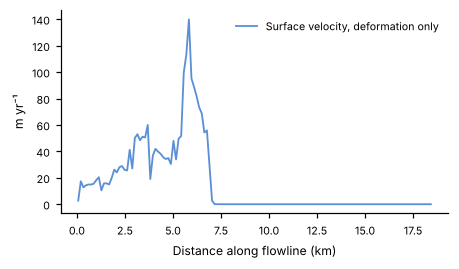

In [6]:
glen_a = gdir.get_diagnostics().get("inversion_glen_a", cfg.PARAMS["glen_a"])
xs, u_def, u_sl = dynamics.velocity_partition(fl, glen_a, fs=0.0)
fig, ax = plt.subplots(figsize=(plotting.WIDTH_1COL * 1.3, 2.4))
ax.plot(xs / 1000, u_def * 5 / 4, color=plotting.ICE, label="Surface velocity, deformation only")
ax.set_xlabel("Distance along flowline (km)")
ax.set_ylabel("m yr⁻¹")
ax.legend(frameon=False)
plotting.test_mode_note(fig)

## A first run: the recent past

`run_from_climate_data` drives the flowline model with the monthly MB model, year by year.
With `store_fl_diagnostics=True` (set in `config.init_oggm`) OGGM saves thickness, velocity and
MB at every grid point every year in `fl_diagnostics*.nc`.

In [7]:
run = config.historical_run(gdir)
tasks.run_from_climate_data(gdir, output_filesuffix="_primer", **run)
with xr.open_dataset(gdir.get_filepath("model_diagnostics", filesuffix="_primer")) as d:
    diag = d.load()
with xr.open_dataset(gdir.get_filepath("fl_diagnostics", filesuffix="_primer"), group=f"fl_{len(gdir.read_pickle('model_flowlines')) - 1}") as d:
    fld = d.load()
diag[["volume_m3", "area_m2", "length_m"]].to_dataframe().iloc[[0, -1]]

,volume_m3,area_m2,length_m,calendar_year,calendar_month,hydro_year,hydro_month
time,,,,,,,
2000.0,1.768167e+09,1.684058e+07,7772.0,2000,1,2000,4
2020.0,1.490931e+09,1.632858e+07,7370.0,2020,1,2020,4


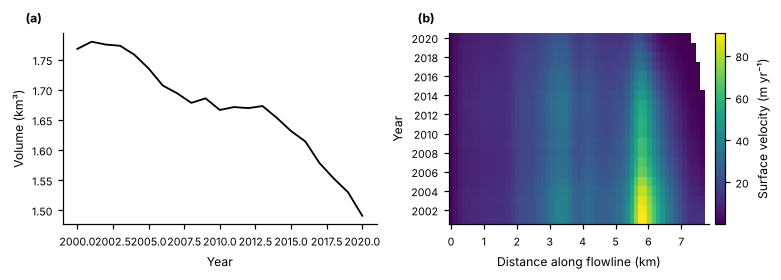

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(plotting.WIDTH_2COL, 2.6))
(diag.volume_m3 / 1e9).plot(ax=axes[0], color="k")
axes[0].set_ylabel("Volume (km³)")
axes[0].set_xlabel("Year")
v = fld["ice_velocity_myr"].where(fld["thickness_m"] > 0)
plotting.hovmoller(axes[1], v.isel(time=slice(1, None)), label="Surface velocity (m yr⁻¹)")
plotting.label_panels(axes)
fig.tight_layout()
plotting.test_mode_note(fig)

**Reading the Hovmöller diagram.** Velocity changes from year to year here only because the
thickness and slope evolve. That is the "geometric" pathway by which a change in rain/snow
partitioning would reach velocity in OGGM. Notebook 03 quantifies it, and notebook 04 adds the
hydrological pathway.